<a href="https://colab.research.google.com/github/Ariqueeezz/klasifikasi-relevansi-teks/blob/main/Proyek_NLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***Libraries***

In [133]:
# Manipulasi Data
import pandas as pd
import numpy as np
import json

# Visualisasi Data
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Splitting & Preprocessing
from transformers import AutoTokenizer
from sklearn.model_selection import train_test_split

# ***Data Loading & EDA Awal Sebelum Preprocessing***

In [84]:
with open(
    "/content/dataset_final_516_format_scraping.json",
    "r",
    encoding="utf-8"
) as f:
    data = json.load(f)

df = pd.DataFrame(data)

df["tweetId"] = df["tweetId"].astype(str)
df["createdAt"] = pd.to_datetime(
    df["createdAt"], utc=True
)

In [85]:
df_eda1 = df.copy()

In [86]:
df_eda1.head()

,type,tweetId,url,text,createdAt,lang,likes,retweets,replies,quotes,...,source,searchQuery,searchType,scrapedAt,relevanceLabel,relevanceLabelName,annotationMethod,annotationVotes,annotationStatus,annotationVersion
0,tweet,2094582774107943183,https://x.com/pendam2/status/2094582774107943183,*Pangdam II/Swj Ikuti Vicon Evaluasi Karhutla ...,2026-09-01 00:27:03+00:00,in,5,3,1,0,...,search,karhutla (kebijakan OR pencegahan OR anggaran ...,Latest,2026-11-02T03:41:54.190Z,0,TIDAK_RELEVAN,UNANIMOUS,"{'annotator1': '0', 'annotator2': '0', 'annota...",FINAL,v1.0
1,tweet,2094586143342051647,https://x.com/ArfZulfikar/status/2094586143342...,“Luas karhutla di Kalimantan 54.564 hektare”\n...,2026-09-01 00:40:26+00:00,in,37,4,0,0,...,search,karhutla (kebijakan OR pencegahan OR anggaran ...,Latest,2026-11-02T03:41:54.190Z,1,RELEVAN,UNANIMOUS,"{'annotator1': '1', 'annotator2': '1', 'annota...",FINAL,v1.0
2,tweet,2094594959232184517,https://x.com/embah72/status/2094594959232184517,Trik Licik pemerintah yg tdk pernah terpikirka...,2026-09-01 01:15:28+00:00,in,89,53,1,1,...,search,karhutla (kebijakan OR pencegahan OR anggaran ...,Latest,2026-11-02T03:41:54.190Z,1,RELEVAN,UNANIMOUS,"{'annotator1': '1', 'annotator2': '1', 'annota...",FINAL,v1.0
3,tweet,2094604008807944614,https://x.com/rapunsey/status/2094604008807944614,setelah Malaysia menyusul Filipina yang ikut t...,2026-09-01 01:51:26+00:00,in,24,7,10,1,...,search,karhutla (pemerintah OR Prabowo OR BNPB OR pen...,Latest,2026-11-02T03:22:24.420Z,1,RELEVAN,UNANIMOUS,"{'annotator1': '1', 'annotator2': '1', 'annota...",FINAL,v1.0
4,tweet,2094605306433347775,https://x.com/Metro_TV/status/2094605306433347775,Pemerintah melalui Kementerian Lingkungan Hidu...,2026-09-01 01:56:35+00:00,in,2,1,0,0,...,search,karhutla (kebijakan OR pencegahan OR anggaran ...,Latest,2026-11-02T03:41:54.190Z,0,TIDAK_RELEVAN,UNANIMOUS,"{'annotator1': '0', 'annotator2': '0', 'annota...",FINAL,v1.0


In [87]:
df_eda1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 516 entries, 0 to 515
Data columns (total 45 columns):
 #   Column              Non-Null Count  Dtype              
---  ------              --------------  -----              
 0   type                516 non-null    object             
 1   tweetId             516 non-null    object             
 2   url                 516 non-null    object             
 3   text                516 non-null    object             
 4   createdAt           516 non-null    datetime64[ns, UTC]
 5   lang                516 non-null    object             
 6   likes               516 non-null    int64              
 7   retweets            516 non-null    int64              
 8   replies             516 non-null    int64              
 9   quotes              516 non-null    int64              
 10  bookmarks           516 non-null    int64              
 11  views               516 non-null    int64              
 12  isRetweet           516 non-null    

## **Pemeriksaan bahwa ID sesuai dengan ID pada URL dan semua tweet tetap unik**

In [89]:
df_eda1["id_dari_url"] = (
    df_eda1["url"].str.extract(r"/status/(\d+)")[0]
)

print("ID tidak cocok:",
      (df_eda1["tweetId"] != df_eda1["id_dari_url"]).sum())

print("ID duplikat:",
      df_eda1["tweetId"].duplicated().sum())

ID tidak cocok: 0
ID duplikat: 0


## **Cek Distribusi Kelas**

/tmp/ipykernel_512/933657397.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="relevanceLabelName", data=df_eda1, palette="Set2")


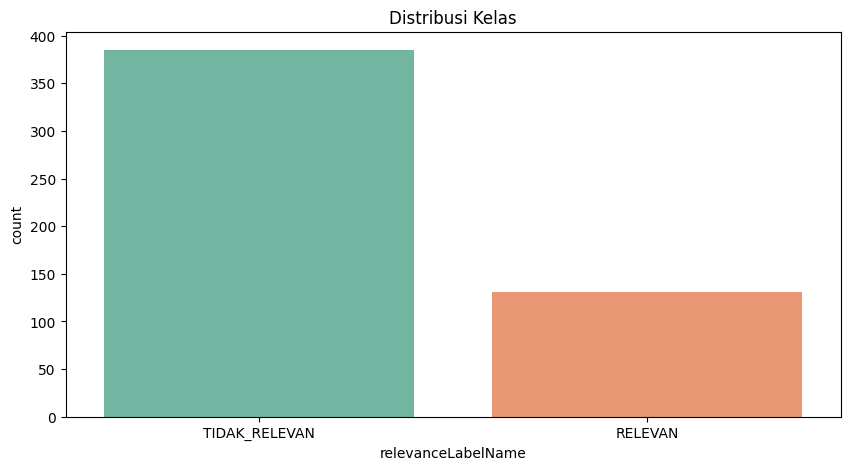

In [90]:
plt.figure(figsize=(10,5))
sns.countplot(x="relevanceLabelName", data=df_eda1, palette="Set2")
plt.title("Distribusi Kelas")
plt.show()

## **Pemeriksaan Missing Value dan Duplikasi**

In [91]:
df_eda1.isnull().sum().sort_values(ascending=False).head(10)

,0
retweetedAuthor,516
retweetedText,516
retweetedTweetId,516
inReplyToTweetId,515
quotedText,476
quotedTweetId,476
quotedAuthor,476
conversationId,1
type,0
tweetId,0


In [92]:
df.duplicated(subset=['tweetId']).sum()

np.int64(0)

In [115]:
df_eda1[df_eda1.duplicated(subset=["text"]) == True]

,type,tweetId,url,text,createdAt,lang,likes,retweets,replies,quotes,...,relevanceLabel,relevanceLabelName,annotationMethod,annotationVotes,annotationStatus,annotationVersion,id_dari_url,panjang_karakter,jumlah_kata,jumlah_token
271,tweet,2098050103055380828,https://x.com/Metro_TV/status/2098050103055380828,Kebakaran hutan dan lahan (karhutla) kembali t...,2026-09-10 14:04:59+00:00,in,9,1,0,0,...,0,TIDAK_RELEVAN,UNANIMOUS,"{'annotator1': '0', 'annotator2': '0', 'annota...",FINAL,v1.0,2098050103055380828,960,131,203
331,tweet,2099756473408774493,https://x.com/HumasPoldaSumut/status/209975647...,Polda Jambi bersama Polres Muaro Jambi dan tim...,2026-09-15 07:05:29+00:00,in,30,0,21,0,...,0,TIDAK_RELEVAN,UNANIMOUS,"{'annotator1': '0', 'annotator2': '0', 'annota...",FINAL,v1.0,2099756473408774493,891,118,164
471,tweet,2103439666145841314,https://x.com/Metro_TV/status/2103439666145841314,Presiden Prabowo Subianto menggelar diskusi st...,2026-09-25 11:01:11+00:00,in,2,1,0,0,...,0,TIDAK_RELEVAN,UNANIMOUS,"{'annotator1': '0', 'annotator2': '0', 'annota...",FINAL,v1.0,2103439666145841314,494,57,102


In [123]:
df_eda1.drop_duplicates(subset=["text"], inplace=True)

print("Data setelah deduplikasi:", len(df_eda1))

Data setelah deduplikasi: 513


## **Cek Distribusi Jumlah Karakter/Huruf dan Kata Tiap Teks**

In [124]:
# Distriusi Karakter termasuk Spasi
df_eda1["text"].apply(len).describe()

,text
count,513.000000
mean,722.664717
std,640.249738
min,82.000000
25%,285.000000
50%,499.000000
75%,975.000000
max,3990.000000


In [125]:
# Distribusi Kata
df_eda1["text"].apply(lambda x : len(str(x).split())).describe()

# teks = "Nicola Tesla"
# len(teks.split())

,text
count,513.000000
mean,95.853801
std,87.182213
min,8.000000
25%,35.000000
50%,66.000000
75%,131.000000
max,555.000000


In [126]:
# Penentuan Max Length di IndoBERT
df_eda1["text"].apply(lambda x : len(str(x).split())).describe(percentiles=[0.75, 0.90, 0.95])

,text
count,513.000000
mean,95.853801
std,87.182213
min,8.000000
50%,66.000000
75%,131.000000
90%,202.000000
95%,270.200000
max,555.000000


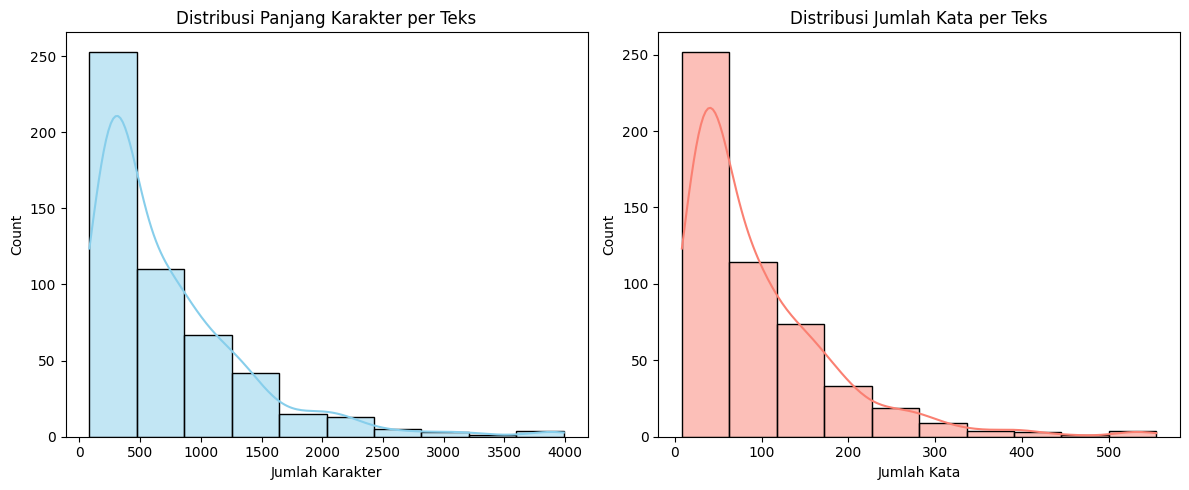

In [127]:
df_eda1["panjang_karakter"] = df_eda1["text"].apply(len)
df_eda1["jumlah_kata"] = df_eda1["text"].apply(lambda x : len(str(x).split()))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot Distribusi Karakter
sns.histplot(df_eda1['panjang_karakter'], bins=10, kde=True, color='skyblue', ax=axes[0])
axes[0].set_title('Distribusi Panjang Karakter per Teks')
axes[0].set_xlabel('Jumlah Karakter')

# Plot Distribusi Kata
sns.histplot(df_eda1['jumlah_kata'], bins=10, kde=True, color='salmon', ax=axes[1])
axes[1].set_title('Distribusi Jumlah Kata per Teks')
axes[1].set_xlabel('Jumlah Kata')

plt.tight_layout()
plt.show()

## **Frekuensi Kata Dasar untuk Identifikasi Noise**

In [128]:
all_text_raw = ' '.join(df_eda1['text'].astype(str))

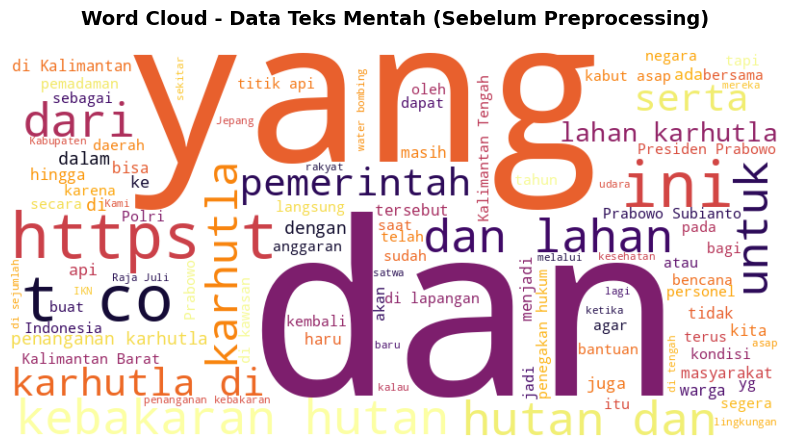

In [129]:
# Membuat objek WordCloud
wordcloud_raw = WordCloud(
    width=800,
    height=400,
    background_color='white',
    colormap='inferno',
    max_words=100
).generate(all_text_raw)

# Menampilkan Word Cloud
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_raw, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud - Data Teks Mentah (Sebelum Preprocessing)', fontsize=14, pad=20, fontweight='bold')
plt.show()

## **Distribusi Panjang Token IndoBERT**

Hasil ini akan membantu kita menentukan panjang input yang realistis sebelum fine-tuning. Jika banyak postingan melampaui batas model, kita perlu merancang strategi pemotongan teks yang tidak menghilangkan bagian evaluatif penting.

In [130]:
tokenizer = AutoTokenizer.from_pretrained(
  "indobenchmark/indobert-base-p1"
)

df_eda1["jumlah_token"] = df_eda1["text"].apply(
  lambda teks: len(
    tokenizer(
      teks,
      add_special_tokens=True,
      truncation=False
    )["input_ids"]
  )
)

df_eda1["jumlah_token"].describe(percentiles=[0.75, 0.90, 0.95, 0.99])

,jumlah_token
count,513.000000
mean,141.978558
std,116.130136
min,29.000000
50%,96.000000
75%,184.000000
90%,290.600000
95%,374.800000
99%,567.400000
max,840.000000


In [131]:
print("Lebih dari 512 token:", (df_eda1["jumlah_token"] > 512).sum())

Lebih dari 512 token: 8


## **Distribusi Panjang Teks Berdasarkan Label**

In [132]:
df_eda1.groupby("relevanceLabel")["jumlah_token"].describe()

,count,mean,std,min,25%,50%,75%,max
relevanceLabel,,,,,,,,
0,382.0,144.209424,111.240196,29.0,65.0,105.5,189.25,739.0
1,131.0,135.473282,129.580823,29.0,61.0,80.0,150.00,840.0


# ***Data Splitting & Data Preprocessing***

In [134]:
# Pemisahan pertama: 70% training, 30% sementara
train_df, temp_df = train_test_split(
  df_eda1,
  test_size=0.30,
  stratify=df_eda1["relevanceLabel"],
  random_state=42
)

# Pemisahan kedua: 15% validation, 15% testing
val_df, test_df = train_test_split(
  temp_df,
  test_size=0.50,
  stratify=temp_df["relevanceLabel"],
  random_state=42
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 359
Validation: 77
Testing: 77


In [135]:
for nama, bagian in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
  print(f"\n{nama}: {len(bagian)} data")
  print(
    bagian["relevanceLabel"]
    .value_counts(normalize=True)
    .round(3)
  )


Train: 359 data
relevanceLabel
0    0.744
1    0.256
Name: proportion, dtype: float64

Validation: 77 data
relevanceLabel
0    0.753
1    0.247
Name: proportion, dtype: float64

Test: 77 data
relevanceLabel
0    0.74
1    0.26
Name: proportion, dtype: float64


In [136]:
train_df.to_csv("train.csv", index=False)
val_df.to_csv("validation.csv", index=False)
test_df.to_csv("test.csv", index=False)